<a href="https://colab.research.google.com/github/sunitishrestha/Graphic/blob/main/asr_nepali_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch;
print('CUDA:', torch.cuda.is_available()) #GPU check	 Confirms the T4 GPU is on

CUDA: True


In [ ]:
!ls -R /content/drive/MyDrive/nepali_asr | head -30


/content/drive/MyDrive/nepali_asr:
runs

/content/drive/MyDrive/nepali_asr/runs:


In [ ]:
%%writefile train_nepali.py
"""Nepali speech-to-text: compare CNN / ResNet / RNN / LSTM / GRU / CRNN / Transformer / Conformer with CTC loss.

Every model = [feature extractor] -> [sequence layers] -> [dense hidden layer] -> [output layer] -> CTC.
Metrics: CTC loss, CER, WER, SER, char/word accuracy, S/D/I breakdown, greedy vs beam-search decoding.

python train_nepali.py --manifest /content/clean/manifest.tsv --models rnn lstm gru cnn resnet resnet_lstm --epochs 30 --out runs
python train_nepali.py --predict file.wav --ckpt runs/resnet_lstm_best.pt
"""
import argparse, csv, json, math, random, time
from collections import defaultdict
from pathlib import Path

import soundfile as sf
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchaudio
from torch.utils.data import DataLoader, Dataset

SR, N_MELS = 16000, 80


# ================================================================ data
def read_manifest(path):
    with open(path, encoding="utf-8") as f:
        return [(r["path"], r["text"].strip()) for r in csv.DictReader(f, delimiter="\t") if r["text"].strip()]


class Vocab:  # character level; index 0 = CTC blank
    def __init__(self, itos):
        self.itos, self.stoi = itos, {c: i for i, c in enumerate(itos)}

    @classmethod
    def from_texts(cls, texts):
        return cls(["<blank>"] + sorted(set("".join(texts))))

    def encode(self, t):
        return [self.stoi[c] for c in t if c in self.stoi]

    def decode(self, ids):
        return "".join(self.itos[i] for i in ids)

    def __len__(self):
        return len(self.itos)


def load_features(path, mel):
    wav, sr = sf.read(path, dtype="float32", always_2d=True)
    wav = torch.from_numpy(wav.mean(1))
    if sr != SR:
        wav = torchaudio.functional.resample(wav, sr, SR)
    feat = torch.log(mel(wav.unsqueeze(0)).squeeze(0) + 1e-6)  # (n_mels, T)
    return (feat - feat.mean()) / (feat.std() + 1e-5)


class SpeechDS(Dataset):
    def __init__(self, rows, vocab, train):
        self.rows, self.vocab, self.train = rows, vocab, train
        self.mel = torchaudio.transforms.MelSpectrogram(SR, n_fft=400, hop_length=160, n_mels=N_MELS)
        self.fm, self.tm = torchaudio.transforms.FrequencyMasking(15), torchaudio.transforms.TimeMasking(30)

    def __len__(self):
        return len(self.rows)

    def __getitem__(self, i):
        path, text = self.rows[i]
        feat = load_features(path, self.mel)
        if self.train:  # SpecAugment
            feat = self.tm(self.fm(feat.unsqueeze(0))).squeeze(0)
        return feat.T.contiguous(), torch.tensor(self.vocab.encode(text)), text


def collate(batch):
    feats, labels, texts = zip(*batch)
    xl = torch.tensor([f.shape[0] for f in feats])
    yl = torch.tensor([len(l) for l in labels])
    return nn.utils.rnn.pad_sequence(feats, batch_first=True), xl, torch.cat(labels), yl, list(texts)


# ================================================================ feature extractors ("feature layers")
def conv_out(n):  # kernel 3, stride 2, pad 1  (also kernel 5, stride 2, pad 2)
    return (n - 1) // 2 + 1


class ConvFront(nn.Module):
    """2 x Conv2d(stride 2): 4x time subsampling (40 ms/frame)."""

    def __init__(self, d):
        super().__init__()
        self.conv = nn.Sequential(nn.Conv2d(1, 32, 3, 2, 1), nn.ReLU(), nn.Conv2d(32, 32, 3, 2, 1), nn.ReLU())
        self.proj = nn.Linear(32 * conv_out(conv_out(N_MELS)), d)

    def forward(self, x, lens):
        x = self.conv(x.unsqueeze(1))
        b, c, t, f = x.shape
        return self.proj(x.permute(0, 2, 1, 3).reshape(b, t, c * f)), conv_out(conv_out(lens)).clamp(min=1)


class BasicBlock(nn.Module):  # ResNet residual block (2D)
    def __init__(self, cin, cout, stride=(1, 1)):
        super().__init__()
        self.c1 = nn.Conv2d(cin, cout, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(cout)
        self.c2 = nn.Conv2d(cout, cout, 3, 1, 1, bias=False); self.b2 = nn.BatchNorm2d(cout)
        self.skip = None
        if stride != (1, 1) or cin != cout:
            self.skip = nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))

    def forward(self, x):
        y = self.b2(self.c2(F.relu(self.b1(self.c1(x)))))
        return F.relu(y + (x if self.skip is None else self.skip(x)))


class ResNetFront(nn.Module):
    """ResNet over the spectrogram. Time is subsampled 4x, mel axis 8x."""

    def __init__(self, d):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(1, 32, 3, 2, 1, bias=False), nn.BatchNorm2d(32), nn.ReLU())
        self.body = nn.Sequential(
            BasicBlock(32, 32), BasicBlock(32, 32),
            BasicBlock(32, 64, (2, 2)), BasicBlock(64, 64),
            BasicBlock(64, 128, (1, 2)), BasicBlock(128, 128))
        f = conv_out(conv_out(conv_out(N_MELS)))
        self.proj = nn.Linear(128 * f, d)

    def forward(self, x, lens):
        x = self.body(self.stem(x.unsqueeze(1)))
        b, c, t, f = x.shape
        return self.proj(x.permute(0, 2, 1, 3).reshape(b, t, c * f)), conv_out(conv_out(lens)).clamp(min=1)


# ================================================================ full models
class Head(nn.Module):  # dense hidden layer + output layer
    def __init__(self, din, d, nvocab):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(din, d), nn.ReLU(), nn.Dropout(0.2), nn.Linear(d, nvocab))

    def forward(self, x):
        return self.net(x)


class CNNModel(nn.Module):
    """Pure 1-D CNN (TDNN/Jasper-like): no recurrence, no residual connections."""

    def __init__(self, nvocab, d=256, layers=8):
        super().__init__()
        self.front = ConvFront(d)
        self.convs = nn.ModuleList([nn.Sequential(nn.Conv1d(d, d, 5, padding=2), nn.BatchNorm1d(d), nn.ReLU(), nn.Dropout(0.1)) for _ in range(layers)])
        self.head = Head(d, d, nvocab)

    def forward(self, x, lens):
        x, lens = self.front(x, lens)
        x = x.transpose(1, 2)
        for c in self.convs:
            x = c(x)
        return self.head(x.transpose(1, 2)), lens


class ResNetModel(nn.Module):
    """ResNet only: residual 2-D CNN + dense layers (no recurrence)."""

    def __init__(self, nvocab, d=256):
        super().__init__()
        self.front = ResNetFront(d)
        self.head = Head(d, d, nvocab)

    def forward(self, x, lens):
        x, lens = self.front(x, lens)
        return self.head(x), lens


class RNNModel(nn.Module):
    """kind: rnn (vanilla tanh) | lstm | gru ; front: conv | resnet (-> CRNN)."""

    def __init__(self, kind, nvocab, d=256, layers=3, bidir=False, front="conv"):
        super().__init__()
        self.front = ConvFront(d) if front == "conv" else ResNetFront(d)
        cls = {"rnn": nn.RNN, "lstm": nn.LSTM, "gru": nn.GRU}[kind]
        self.rnn = cls(d, d, layers, batch_first=True, bidirectional=bidir, dropout=0.2)
        self.head = Head(d * (2 if bidir else 1), d, nvocab)

    def forward(self, x, lens):
        x, lens = self.front(x, lens)
        x = nn.utils.rnn.pack_padded_sequence(x, lens.cpu(), batch_first=True, enforce_sorted=False)
        x, _ = self.rnn(x)
        x, _ = nn.utils.rnn.pad_packed_sequence(x, batch_first=True)
        return self.head(x), lens


class PosEnc(nn.Module):
    def __init__(self, d, maxlen=5000):
        super().__init__()
        pe = torch.zeros(maxlen, d)
        pos, div = torch.arange(maxlen).unsqueeze(1), torch.exp(torch.arange(0, d, 2) * (-math.log(10000.0) / d))
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe)

    def forward(self, x):
        return x + self.pe[: x.size(1)]


class TransformerModel(nn.Module):
    def __init__(self, nvocab, d=256, layers=6, heads=4):
        super().__init__()
        self.front, self.pos = ConvFront(d), PosEnc(d)
        layer = nn.TransformerEncoderLayer(d, heads, 4 * d, 0.1, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.head = Head(d, d, nvocab)

    def forward(self, x, lens):
        x, lens = self.front(x, lens)
        mask = torch.arange(x.size(1), device=x.device)[None] >= lens[:, None]
        return self.head(self.enc(self.pos(x), src_key_padding_mask=mask)), lens


class ConformerModel(nn.Module):
    def __init__(self, nvocab, d=256, layers=6, heads=4):
        super().__init__()
        self.front = ConvFront(d)
        self.enc = torchaudio.models.Conformer(d, heads, 4 * d, layers, depthwise_conv_kernel_size=15, dropout=0.1)
        self.head = Head(d, d, nvocab)

    def forward(self, x, lens):
        x, lens = self.front(x, lens)
        x, lens = self.enc(x, lens)
        return self.head(x), lens


MODELS = {
    "cnn": lambda v: CNNModel(v),
    "resnet": lambda v: ResNetModel(v),
    "rnn": lambda v: RNNModel("rnn", v),
    "lstm": lambda v: RNNModel("lstm", v),
    "gru": lambda v: RNNModel("gru", v),
    "bilstm": lambda v: RNNModel("lstm", v, bidir=True),
    "cnn_lstm": lambda v: RNNModel("lstm", v, front="conv", bidir=True),      # conv front + BiLSTM
    "resnet_lstm": lambda v: RNNModel("lstm", v, front="resnet", bidir=True),  # ResNet + BiLSTM (CRNN)
    "transformer": lambda v: TransformerModel(v),
    "conformer": lambda v: ConformerModel(v),
}
LR = {"rnn": 5e-4, "transformer": 5e-4, "conformer": 5e-4}


# ================================================================ error calculation
def edit_distance(a, b):
    d = list(range(len(b) + 1))
    for i in range(1, len(a) + 1):
        prev, d[0] = d[0], i
        for j in range(1, len(b) + 1):
            cur = d[j]
            d[j] = min(d[j] + 1, d[j - 1] + 1, prev + (a[i - 1] != b[j - 1]))
            prev = cur
    return d[-1]


def lev_ops(ref, hyp):
    """Return (substitutions, deletions, insertions)."""
    n, m = len(ref), len(hyp)
    d = [[0] * (m + 1) for _ in range(n + 1)]
    for i in range(n + 1):
        d[i][0] = i
    for j in range(m + 1):
        d[0][j] = j
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            d[i][j] = min(d[i - 1][j] + 1, d[i][j - 1] + 1, d[i - 1][j - 1] + (ref[i - 1] != hyp[j - 1]))
    i, j, S, D, I = n, m, 0, 0, 0
    while i > 0 or j > 0:
        if i > 0 and j > 0 and d[i][j] == d[i - 1][j - 1] + (ref[i - 1] != hyp[j - 1]):
            S += ref[i - 1] != hyp[j - 1]; i -= 1; j -= 1
        elif i > 0 and d[i][j] == d[i - 1][j] + 1:
            D += 1; i -= 1
        else:
            I += 1; j -= 1
    return S, D, I


def metrics(refs, hyps, detailed=False):
    ce = cn = we = wn = se = 0
    S = D = I = 0
    for r, h in zip(refs, hyps):
        ce += edit_distance(r, h); cn += max(len(r), 1)
        we += edit_distance(r.split(), h.split()); wn += max(len(r.split()), 1)
        se += int(r != h)
        if detailed:
            s, d, i = lev_ops(r, h); S += s; D += d; I += i
    out = {"CER": ce / cn, "WER": we / wn, "SER": se / max(len(refs), 1)}
    out["char_acc"], out["word_acc"] = 1 - out["CER"], 1 - out["WER"]
    if detailed:
        out.update(sub_rate=S / cn, del_rate=D / cn, ins_rate=I / cn)
    return out


# ================================================================ decoding
def greedy_decode(logp, lens, vocab):
    ids, outs = logp.argmax(-1).cpu(), []
    for seq, l in zip(ids, lens.cpu()):
        prev, s = 0, []
        for t in seq[: int(l)].tolist():
            if t != prev and t != 0:
                s.append(t)
            prev = t
        outs.append(vocab.decode(s))
    return outs


def _lse(a, b):
    NEG = -1e30
    if a <= NEG: return b
    if b <= NEG: return a
    m = max(a, b)
    return m + math.log(math.exp(a - m) + math.exp(b - m))


def beam_decode(logp, vocab, beam=10, topk=8):
    """CTC prefix beam search. logp: (T, V) log-probabilities as nested lists / tensor. No language model."""
    NEG = -1e30
    beams = {(): [0.0, NEG]}  # prefix -> [log p(ends in blank), log p(ends in char)]
    for row in logp:
        row = list(row)
        if row[0] > -1e-3:
            cand = [0]
        else:
            cand = sorted(range(len(row)), key=lambda c: -row[c])[:topk]
            if 0 not in cand:
                cand.append(0)
        nb = defaultdict(lambda: [NEG, NEG])
        for prefix, (pb, pnb) in beams.items():
            ptot = _lse(pb, pnb)
            for c in cand:
                p = row[c]
                if c == 0:
                    n = nb[prefix]; n[0] = _lse(n[0], ptot + p)
                else:
                    last = prefix[-1] if prefix else None
                    n = nb[prefix + (c,)]
                    if c == last:
                        n[1] = _lse(n[1], pb + p)                      # repeat separated by blank -> new char
                        m = nb[prefix]; m[1] = _lse(m[1], pnb + p)    # repeat without blank -> same char
                    else:
                        n[1] = _lse(n[1], ptot + p)
        beams = dict(sorted(nb.items(), key=lambda kv: _lse(*kv[1]), reverse=True)[:beam])
    best = max(beams.items(), key=lambda kv: _lse(*kv[1]))[0]
    return vocab.decode(list(best))


# ================================================================ train / eval
def forward_logp(model, x, xl, amp):
    with torch.autocast("cuda", enabled=amp):
        logits, ol = model(x, xl)
    return logits.float().log_softmax(-1), ol


@torch.no_grad()
def evaluate(model, loader, vocab, dev, ctc, amp, keep=0):
    model.eval()
    refs, hyps, loss_sum, n, kept = [], [], 0.0, 0, []
    for x, xl, y, yl, texts in loader:
        logp, ol = forward_logp(model, x.to(dev), xl.to(dev), amp)
        loss_sum += ctc(logp.transpose(0, 1), y, ol.cpu(), yl).item(); n += 1
        refs += texts; hyps += greedy_decode(logp, ol, vocab)
        for k in range(len(texts)):
            if len(kept) < keep:
                kept.append(logp[k, : int(ol[k])].cpu().tolist())
    return loss_sum / max(n, 1), refs, hyps, kept


def train_one(kind, args, train_rows, val_rows, vocab, dev):
    amp = dev == "cuda" and not args.no_amp
    mk = lambda rows, tr: DataLoader(SpeechDS(rows, vocab, tr), args.batch, shuffle=tr, collate_fn=collate, num_workers=args.workers, persistent_workers=args.workers > 0)
    train_dl, val_dl = mk(train_rows, True), mk(val_rows, False)
    model = MODELS[kind](len(vocab)).to(dev)
    params = sum(p.numel() for p in model.parameters()) / 1e6
    print(f"\n=== {kind}: {params:.2f}M parameters ===")
    lr = LR.get(kind, args.lr)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=lr, total_steps=args.epochs * len(train_dl), pct_start=0.15)
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    ctc = nn.CTCLoss(blank=0, zero_infinity=True)
    out = Path(args.out); out.mkdir(parents=True, exist_ok=True)
    ckpt, best, hist, t0 = out / f"{kind}_best.pt", None, [], time.time()

    for ep in range(1, args.epochs + 1):
        model.train(); tot = 0.0
        for x, xl, y, yl, _ in train_dl:
            logp, ol = forward_logp(model, x.to(dev), xl.to(dev), amp)
            loss = ctc(logp.transpose(0, 1), y, ol.cpu(), yl)
            opt.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update(); sched.step()
            tot += loss.item()
        vloss, refs, hyps, _ = evaluate(model, val_dl, vocab, dev, ctc, amp)
        m = metrics(refs, hyps)
        hist.append(dict(epoch=ep, train_loss=tot / len(train_dl), val_loss=vloss, **m))
        print(f"ep {ep:3d} | train CTC {tot/len(train_dl):.3f} | val CTC {vloss:.3f} | CER {m['CER']*100:5.1f}% | WER {m['WER']*100:5.1f}% | char-acc {m['char_acc']*100:5.1f}%")
        if best is None or m["CER"] < best:
            best = m["CER"]
            torch.save({"model": model.state_dict(), "itos": vocab.itos, "kind": kind}, ckpt)

    with open(out / f"{kind}_history.csv", "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=list(hist[0])); w.writeheader(); w.writerows(hist)

    # ---- final, detailed evaluation with the best checkpoint
    model.load_state_dict(torch.load(ckpt, map_location=dev)["model"])
    vloss, refs, hyps, kept = evaluate(model, val_dl, vocab, dev, ctc, amp, keep=args.beam_utts)
    g = metrics(refs, hyps, detailed=True)
    n = len(kept)
    gs = metrics(refs[:n], hyps[:n])
    bs = metrics(refs[:n], [beam_decode(lp, vocab, args.beam) for lp in kept])
    print(f"sample  REF: {refs[0]}\n        HYP: {hyps[0]}")
    res = dict(model=kind, params_M=round(params, 2), minutes=round((time.time() - t0) / 60, 1), val_ctc_loss=vloss, **g,
               CER_greedy_sub=gs["CER"], CER_beam_sub=bs["CER"], WER_greedy_sub=gs["WER"], WER_beam_sub=bs["WER"])
    return res


def predict(args, dev):
    ck = torch.load(args.ckpt, map_location=dev)
    vocab = Vocab(ck["itos"])
    model = MODELS[ck["kind"]](len(vocab)).to(dev); model.load_state_dict(ck["model"]); model.eval()
    mel = torchaudio.transforms.MelSpectrogram(SR, n_fft=400, hop_length=160, n_mels=N_MELS)
    x = load_features(args.predict, mel).T.unsqueeze(0).to(dev)
    with torch.no_grad():
        logp, ol = model(x, torch.tensor([x.shape[1]], device=dev))
        logp = logp.log_softmax(-1)
    print("greedy:", greedy_decode(logp, ol, vocab)[0])
    print("beam  :", beam_decode(logp[0].cpu().tolist(), vocab, args.beam))


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--manifest", default="/content/clean/manifest.tsv")
    ap.add_argument("--models", nargs="+", default=["rnn", "lstm", "gru", "cnn", "resnet", "resnet_lstm"], choices=list(MODELS))
    ap.add_argument("--epochs", type=int, default=30)
    ap.add_argument("--batch", type=int, default=32)
    ap.add_argument("--lr", type=float, default=1e-3)
    ap.add_argument("--workers", type=int, default=2)
    ap.add_argument("--val_split", type=float, default=0.05)
    ap.add_argument("--beam", type=int, default=10)
    ap.add_argument("--beam_utts", type=int, default=300, help="validation utterances used for the beam-search comparison")
    ap.add_argument("--no_amp", action="store_true")
    ap.add_argument("--out", default="runs")
    ap.add_argument("--predict"); ap.add_argument("--ckpt")
    args = ap.parse_args()
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    print("device:", dev)
    if args.predict:
        return predict(args, dev)

    random.seed(0); torch.manual_seed(0)
    rows = read_manifest(args.manifest); random.shuffle(rows)
    nval = max(1, int(len(rows) * args.val_split))
    val_rows, train_rows = rows[:nval], rows[nval:]
    vocab = Vocab.from_texts([t for _, t in train_rows])
    Path(args.out).mkdir(parents=True, exist_ok=True)
    json.dump(vocab.itos, open(Path(args.out) / "vocab.json", "w", encoding="utf-8"), ensure_ascii=False)
    print(f"train {len(train_rows)} | val {len(val_rows)} | characters in vocab {len(vocab)}")

    results = [train_one(k, args, train_rows, val_rows, vocab, dev) for k in args.models]

    cols = ["model", "params_M", "minutes", "val_ctc_loss", "CER", "WER", "SER", "char_acc", "word_acc", "sub_rate", "del_rate", "ins_rate",
            "CER_greedy_sub", "CER_beam_sub", "WER_greedy_sub", "WER_beam_sub"]
    rpath, merged = Path(args.out) / "results.csv", {}
    if rpath.exists():  # keep results of models trained in earlier runs
        with open(rpath, encoding="utf-8") as f:
            merged = {r["model"]: r for r in csv.DictReader(f)}
    for r in results:
        merged[r["model"]] = {c: r[c] for c in cols}
    with open(rpath, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=cols); w.writeheader(); w.writerows(merged.values())
    print("\n" + "=" * 24 + " RESULTS " + "=" * 24)
    print(f"{'model':12s}{'params':>7s}{'CTC':>7s}{'CER%':>7s}{'WER%':>7s}{'SER%':>7s}{'charAcc%':>9s}{'beamCER%':>9s}")
    for r in results:
        print(f"{r['model']:12s}{r['params_M']:>7}{r['val_ctc_loss']:>7.2f}{r['CER']*100:>7.1f}{r['WER']*100:>7.1f}{r['SER']*100:>7.1f}{r['char_acc']*100:>9.1f}{r['CER_beam_sub']*100:>9.1f}")


if __name__ == "__main__":
    main()

Overwriting train_nepali.py


In [ ]:
%%writefile preprocess.py

"""Clean an OpenSLR speech dataset: normalise audio + text, remove outliers, write manifest.tsv.

python preprocess.py --audio_dir /content/raw --transcripts /content/raw/all_transcripts.txt --out_dir /content/clean

Transcript line formats accepted:  id<TAB>text | id<TAB>speaker<TAB>text | id text
"""
import argparse, re, unicodedata
from collections import Counter
from pathlib import Path

import librosa
import numpy as np
import pandas as pd
import soundfile as sf
from joblib import Parallel, delayed

SR = 16000


def clean_text(t):
    t = unicodedata.normalize("NFC", t).lower()
    # keep letters, combining marks (needed for Indic scripts), numbers, space, apostrophe
    t = "".join(c for c in t if unicodedata.category(c) != "Cf")  # drop ZWJ/ZWNJ etc. (don't split words)
    t = "".join(c if (unicodedata.category(c)[0] in "LMN" or c in " '") else " " for c in t)  # Devanagari letters+matras kept, danda/punctuation removed
    return re.sub(r"\s+", " ", t).strip()


def read_transcripts(files):
    out = {}
    for fn in files:
        with open(fn, encoding="utf-8") as f:
            for line in f:
                line = line.rstrip("\n")
                if not line.strip():
                    continue
                parts = line.split("\t") if "\t" in line else line.split(" ", 1)
                if len(parts) >= 2:
                    out[Path(parts[0].strip()).stem] = parts[-1].strip()
    return out


def process(uid, path, text, wav_dir):
    try:
        y, sr = sf.read(str(path), dtype="float32", always_2d=True)
        y = y.mean(1)
        if sr != SR:
            y = librosa.resample(y, orig_sr=sr, target_sr=SR)
        y, _ = librosa.effects.trim(y, top_db=30)  # cut leading/trailing silence
        if len(y) < SR * 0.2:
            return None
        dur = len(y) / SR
        rms_db = 20 * np.log10(np.sqrt(np.mean(y ** 2)) + 1e-9)
        clip = float(np.mean(np.abs(y) >= 0.99))
        peak = np.abs(y).max()
        y = y / peak * 0.95  # peak-normalise
        out = Path(wav_dir) / f"{uid}.wav"
        sf.write(str(out), y, SR)
        return dict(id=uid, path=str(out), text=text, dur=dur, rms_db=rms_db, clip_ratio=clip, cps=len(text) / dur)
    except Exception:
        return None


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument("--audio_dir", required=True)
    ap.add_argument("--transcripts", nargs="+", required=True)
    ap.add_argument("--out_dir", default="/content/clean")
    ap.add_argument("--min_sec", type=float, default=1.0)
    ap.add_argument("--max_sec", type=float, default=15.0)
    ap.add_argument("--min_db", type=float, default=-50.0, help="drop clips quieter than this RMS (dBFS)")
    ap.add_argument("--max_clip", type=float, default=0.01, help="drop if >1%% samples clipped")
    ap.add_argument("--mad_k", type=float, default=3.5, help="speech-rate outlier cutoff (robust z-score)")
    ap.add_argument("--min_char_count", type=int, default=5, help="drop utterances containing very rare characters")
    ap.add_argument("--jobs", type=int, default=-1)
    a = ap.parse_args()

    out = Path(a.out_dir); wav_dir = out / "wavs"; wav_dir.mkdir(parents=True, exist_ok=True)

    audio = {}
    for ext in ("*.wav", "*.flac", "*.mp3"):
        for p in Path(a.audio_dir).rglob(ext):
            audio[p.stem] = p
    trans = read_transcripts(a.transcripts)
    pairs = [(u, audio[u], clean_text(t)) for u, t in trans.items() if u in audio]
    print(f"audio files: {len(audio)} | transcripts: {len(trans)} | matched: {len(pairs)}")

    res = Parallel(n_jobs=a.jobs, verbose=1)(delayed(process)(u, p, t, wav_dir) for u, p, t in pairs)
    df = pd.DataFrame([r for r in res if r])
    print(f"readable audio: {len(df)} (unreadable/too-short: {len(pairs) - len(df)})")

    df["removed_reason"] = ""

    def flag(mask, reason):
        m = mask & (df.removed_reason == "")
        df.loc[m, "removed_reason"] = reason
        print(f"  {reason:<18s}{int(m.sum()):>7d}")

    print("removed by rule:")
    flag(df.text.str.len() < 2, "empty_text")
    flag(df.dur < a.min_sec, "too_short")
    flag(df.dur > a.max_sec, "too_long")
    flag(df.rms_db < a.min_db, "too_quiet")
    flag(df.clip_ratio > a.max_clip, "clipped")

    ok = df[df.removed_reason == ""]
    med = ok.cps.median(); mad = (ok.cps - med).abs().median() * 1.4826 + 1e-9
    flag(((df.cps - med).abs() / mad) > a.mad_k, "bad_speech_rate")  # text doesn't match audio length

    cnt = Counter("".join(df[df.removed_reason == ""].text))
    rare = {c for c, n in cnt.items() if n < a.min_char_count}
    if rare:
        flag(df.text.apply(lambda s: any(c in rare for c in s)), "rare_char")

    keep = df[df.removed_reason == ""]
    keep[["path", "text"]].to_csv(out / "manifest.tsv", sep="\t", index=False)
    df.to_csv(out / "report.csv", index=False)
    print(f"\nKEPT {len(keep)}/{len(df)} utterances = {keep.dur.sum()/3600:.2f} hours | chars: {len(cnt) - len(rare)}")
    print(f"manifest: {out/'manifest.tsv'}   report: {out/'report.csv'}")


if __name__ == "__main__":
    main()

Overwriting preprocess.py


In [ ]:
PARTS=['0','1','2','3','4','5','a','b','c','d'] # part of download file
BASE='https://www.openslr.org/resources/54'
!mkdir -p /content/raw
!cd /content/raw && wget -c --show-progress {BASE}/utt_spk_text.tsv #wget: download a file from the internet.  -q: reduce ordinary download messages.  -c: resume an interrupted download when possible. --show-progress: show the download progress.
for p in PARTS:
  !cd /content/raw && wget -c -q --show-progress {BASE}asr_nepali_{p}.zip && unzip -q -o asr_nepali_{p}.zip && rm asr_nepali_{p}.zip
!echo "flac files:"; find/content/raw -name '*.flac' | wc -l
!head -n 3 /content/raw/utt_spk_text.tsv

--2026-10-12 13:22:29--  https://www.openslr.org/resources/54/utt_spk_text.tsv
Resolving www.openslr.org (www.openslr.org)... 136.243.171.4
Connecting to www.openslr.org (www.openslr.org)|136.243.171.4|:443... connected.
HTTP request sent, awaiting response... 416 Requested Range Not Satisfiable

    The file is already fully retrieved; nothing to do.

flac files:
/bin/bash: line 1: find/content/raw: No such file or directory
0
4aa1fdca33	6a6d1	००७ मिलको दूरीमा
86e521554a	1f680	००७ मिलको दूरीमा
c96b2b1afb	e349f	००७ मिलको दूरीमा


In [ ]:
# !cd /content/raw && unzip -q -o asr_nepali_0.zip && rm asr_nepali_0.zip
# !find /content/raw -name "*.flac" | wc -l

!cd /content/raw && unzip -q -o asr_nepali_1.zip && rm asr_nepali_1.zip
!cd /content/raw && unzip -q -o asr_nepali_2.zip && rm asr_nepali_2.zip
!cd /content/raw && unzip -q -o asr_nepali_a.zip && rm asr_nepali_a.zip
!cd /content/raw && unzip -q -o asr_nepali_b.zip && rm asr_nepali_b.zip

!find /content/raw -name "*.flac" | wc -l

49579


ls: cannot access '/content/raw/*.zip': No such file or directory


In [ ]:
!python train_nepali.py --manifest /content/clean/manifest.tsv --models rnn lstm --epochs 30 --out /content/drive/MyDrive/nepali_asr/runs

device: cuda
train 45698 | val 2405 | characters in vocab 71

=== rnn: 0.65M parameters ===
/content/train_nepali.py:392: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scaler.step(opt); scaler.update(); sched.step()
ep   1 | train CTC 4.233 | val CTC 3.601 | CER  96.0% | WER 100.0% | char-acc   4.0%
ep   2 | train CTC 3.502 | val CTC 3.311 | CER  86.9% | WER 100.0% | char-acc  13.1%
ep   3 | train CTC 2.969 | val CTC 2.300 | CER  67.1% | WER  99.7% | char-acc  32.9%
ep   4 | train CTC 2.270 | val CTC 1.801 | CER  52.8% | WER  99.8% | char-acc  47.2%
ep   5 | train CTC 2.007 | val CTC 1.612 | CER  47.1% | WER  98.6% | char-acc  52.9%
ep   6 | trai

removed_reason
KEPT               48103
too_short           1308
too_quiet             94
clipped               31
too_long              16
bad_speech_rate       16
rare_char              8
empty_text             3
Name: count, dtype: int64


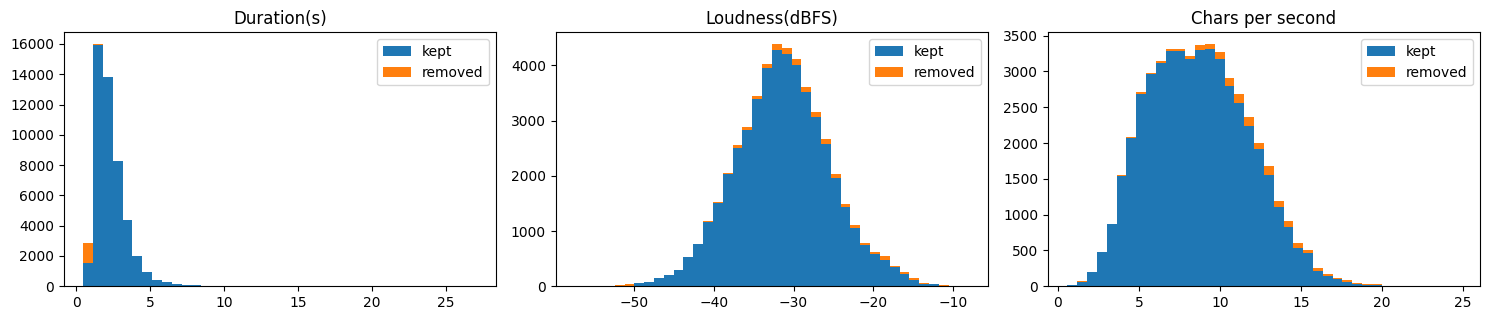

                                 path                                                                              text
0  /content/clean/wavs/2f7ab41953.wav                                                              ०११ देखि काङ्ग्रेसको
1  /content/clean/wavs/1d7f225bd0.wav                                                                          ०२३ सम्म
2  /content/clean/wavs/b6c37578d2.wav                                                                          ०२३ सम्म
3  /content/clean/wavs/2bedce5635.wav                                                                      ०२४ देखि वाम
4  /content/clean/wavs/0ba8e6bacd.wav                                                                ०३१ सालमा पञ्चायती
5  /content/clean/wavs/a7f5ba44bb.wav  ०३६ देखि नै राजनीतिमा लाग्नुभएका गुरुङ ०४२ मा अखिल छैठौँको अध्यक्ष हुनुभएको थियो
6  /content/clean/wavs/0d7fef5a4c.wav                                                               ०४६ सालको जनआन्दोलन
7  /content/clean/wavs/142063b43f.wav   

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv('/content/clean/report.csv');
df['kept']=df.removed_reason.isna()
print(df.removed_reason.fillna('KEPT').value_counts())
fig,ax=plt.subplots(1,3,figsize=(15,3.3))
for a_,col ,t in zip(ax,['dur','rms_db','cps'],['Duration(s)','Loudness(dBFS)','Chars per second']):
   a_.hist([df[df.kept][col], df[~df.kept][col]], bins=40, label=['kept', 'removed'], stacked=True); a_.set_title(t); a_.legend()
plt.tight_layout(); plt.show()
m = pd.read_csv('/content/clean/manifest.tsv', sep='\t')
print(m.head(5).to_string())
print('Nepali characters in vocabulary:', len(set(''.join(m.text))))


In [ ]:
!python preprocess.py --audio_dir /content/raw --transcripts /content/raw/utt_spk_text.tsv --out_dir /content/clean --min_sec 1 --max_sec 15 --min_db -50 --max_clip 0.01 --mad_k 3.5 --min_char_count 5

audio files: 49579 | transcripts: 157905 | matched: 49579
[Parallel(n_jobs=-1)]: Using backend LokyBackend with 2 concurrent workers.
[Parallel(n_jobs=-1)]: Done 150 tasks      | elapsed:   30.6s
[Parallel(n_jobs=-1)]: Done 2550 tasks      | elapsed:   43.2s
[Parallel(n_jobs=-1)]: Done 6550 tasks      | elapsed:  1.1min
[Parallel(n_jobs=-1)]: Done 12150 tasks      | elapsed:  1.5min
[Parallel(n_jobs=-1)]: Done 19350 tasks      | elapsed:  2.1min
[Parallel(n_jobs=-1)]: Done 28150 tasks      | elapsed:  2.9min
[Parallel(n_jobs=-1)]: Done 38550 tasks      | elapsed:  3.8min
[Parallel(n_jobs=-1)]: Done 49579 out of 49579 | elapsed:  4.7min finished
readable audio: 49579 (unreadable/too-short: 0)
removed by rule:
  empty_text              3
  too_short            1308
  too_long               16
  too_quiet              94
  clipped                31
  bad_speech_rate        16
  rare_char               8

KEPT 48103/49579 utterances = 31.61 hours | chars: 70
manifest: /content/clean/manife

In [ ]:
!ls -lh /content/raw
!find /content/raw -name "*.flac" | wc -l

!ls -lh /content/raw

total 11M
drwxr-xr-x 3 root root 4.0K Oct 12 14:17 asr_nepali
-rw-r--r-- 1 root root  11M Jun 29  2018 utt_spk_text.tsv
49579
total 11M
drwxr-xr-x 3 root root 4.0K Oct 12 14:17 asr_nepali
-rw-r--r-- 1 root root  11M Jun 29  2018 utt_spk_text.tsv


# New Section

In [ ]:
!cd /content/drive/MyDrive/nepali_asr/ && zip -rq /content/runs.zip runs
from google.colab import files
files.download('/content/runs.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
os.makedirs('/content/drive/MyDrive/nepali_asr/runs', exist_ok=True) #create a file in personal drive
P = '/content/drive/MyDrive/nepali_asr'
!pip -q install soundfile librosa joblib pandas matplotlib

In [ ]:
!cd /content/raw && wget -c https://www.openslr.org/resources/54/asr_nepali_1.zip
!cd /content/raw && wget -c https://www.openslr.org/resources/54/asr_nepali_2.zip
!cd /content/raw && wget -c https://www.openslr.org/resources/54/asr_nepali_a.zip
!cd /content/raw && wget -c https://www.openslr.org/resources/54/asr_nepali_b.zip





--2026-10-12 13:30:15--  https://www.openslr.org/resources/54/asr_nepali_1.zip
Resolving www.openslr.org (www.openslr.org)... 136.243.171.4
Connecting to www.openslr.org (www.openslr.org)|136.243.171.4|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 582088242 (555M) [application/zip]
Saving to: ‘asr_nepali_1.zip’

asr_nepali_1.zip    100%[===================>] 555.12M  1.82MB/s    in 7m 40s  

2026-10-12 13:37:56 (1.21 MB/s) - ‘asr_nepali_1.zip’ saved [582088242/582088242]

--2026-10-12 13:37:57--  https://www.openslr.org/resources/54/asr_nepali_2.zip
Resolving www.openslr.org (www.openslr.org)... 136.243.171.4
Connecting to www.openslr.org (www.openslr.org)|136.243.171.4|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 589401540 (562M) [application/zip]
Saving to: ‘asr_nepali_2.zip’

asr_nepali_2.zip    100%[===================>] 562.10M  1.01MB/s    in 7m 51s  

2026-10-12 13:45:48 (1.19 MB/s) - ‘asr_nepali_2.zip’ saved [589401540/58

In [ ]:
!nvidia-smi | head -n 12


Mon Oct 12 11:56:22 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   48C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----